# Laboratorio N°3 – Circuito 1 – Caso 2: amplificador compuesto **VFA + CFA** (LM324 + LM6181)

**Qué hace este cuaderno:** diseña el amplificador compuesto VFA + CFA, calcula todo lo que pide la consigna (puntos b.1 a b.4), grafica los diagramas de Bode y la respuesta al escalón, y arma la tabla final comparando **teoría vs. simulación (LTSpice)**.

**Cómo usarlo:** ejecutá las celdas de arriba hacia abajo (`Run All`). Antes de cada celda de código hay un bloque de texto que explica qué hace. La única celda que hay que editar a mano es la de las mediciones de LTSpice (sección 7); mientras no se carguen, esos valores quedan en `None` y las tablas muestran `--`.

| Consigna | Qué se hace | Sección |
|---|---|---|
| b.1 Diseñar el compuesto VFA + CFA para MPM y $f_g\approx2$ MHz (considerando el 2° polo del VFA) | Calcular la ganancia del CFA, $R_1$, $R_2$, $R_f$ y verificar la condición de MPM | 2 |
| b.2 Calcular BW potencial, polo de lazo cerrado y BW a −3 dB | Fórmulas analíticas + verificación numérica | 3, 4, 5 |
| b.3 Medir el BW a −3 dB | Se carga el valor medido en LTSpice y se compara | 7, 9 |
| b.4 Estimar el margen de fase desde el escalón | Sobrepico → ζ → margen de fase | 8 |

**Circuito:** A01 = LM324 (VFA, dos polos) con realimentación global $R_i$–$R_f$; A02 = LM6181 (CFA) dentro del lazo con realimentación local $R_1$–$R_2$. Ambos son no inversores.

## 1. Preparación

La siguiente celda carga las librerías de Python que se usan:

* `numpy`: cálculos con números y polinomios.
* `matplotlib`: gráficos.
* `pandas`: tablas.
* `scipy.signal`: simula la respuesta al escalón.

También crea la carpeta `salidas_caso2` donde se guardan las figuras y tablas para el informe.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import signal
from IPython.display import display

plt.rcParams.update({'figure.figsize': (10, 6), 'axes.grid': True, 'grid.alpha': 0.4, 'font.size': 11})

CARPETA = 'salidas_caso2'
os.makedirs(CARPETA, exist_ok=True)
print('Listo. Las figuras y tablas se guardarán en la carpeta:', CARPETA)

Listo. Las figuras y tablas se guardarán en la carpeta: salidas_caso2


## 2. Datos y diseño (consigna b.1)

### 2.1 Datos de partida

* **LM324 (VFA):** $A_{d0}=100$ dB, $f_1=10$ Hz, $f_2=5{,}06$ MHz, y $f_T=A_{d0}\,f_1=1$ MHz.
* **LM6181 (CFA):** transresistencia $R_t=2{,}37$ MΩ y transimpedancia con dos polos, $f_{t1}=14$ kHz y $f_{t2}=82{,}3$ MHz. La transcapacitancia sale de $C_t=1/(2\pi R_t f_{t1})\approx4{,}8$ pF.
* **Resistencia del terminal inversor del CFA, $r_i$:** **no la publica el fabricante**. Se supone $r_i=20\ \Omega$ (apunte, Cap. III). Más adelante (sección 6) se muestra cuánto cambian los resultados si fuera otro valor.
* **$R_2=820\ \Omega$:** valor recomendado por el fabricante para el LM6181 (el apunte indica del orden de 1 kΩ). Fija el ancho de banda del CFA y su estabilidad (ver 2.3).
* **Requerimientos:** $A_{vf}=20$ dB, máxima planicidad de módulo (MPM) y ancho de banda potencial **$f_g\approx2$ MHz**.
* **$R_i=1$ kΩ:** resistencia a tierra del lazo global (libre elección; es el valor que usa el esquemático de LTSpice).

In [2]:
# --- LM324 (VFA) ---
Ad0_dB = 100.0          # ganancia de lazo abierto [dB]
f1 = 10.0               # primer polo [Hz]
f2 = 5.06e6             # segundo polo [Hz]
Ad0 = 10**(Ad0_dB/20)   # ganancia de lazo abierto en veces
fT = Ad0*f1             # producto ganancia-ancho de banda [Hz]

# --- LM6181 (CFA) ---
Rt  = 2.37e6            # transresistencia [ohm]
ft1 = 14e3              # primer polo de Zt [Hz]
ft2 = 82.3e6            # segundo polo de Zt [Hz]
Ct  = 1/(2*np.pi*Rt*ft1)  # transcapacitancia [F]
ri  = 20.0              # resistencia del terminal inversor [ohm]  <-- SUPUESTO (no publicada)
R2  = 820.0             # realimentación del CFA [ohm] (recomendada por el fabricante)

# --- Requerimientos ---
Avf_dB = 20.0           # ganancia global pedida [dB]
fg_obj = 2e6            # ancho de banda potencial buscado [Hz]
Ri = 1e3                # a tierra, lazo global [ohm]

print(f'Ad0 = {Ad0:,.0f} V/V  |  fT = {fT/1e6:.2f} MHz  |  Ct = {Ct*1e12:.2f} pF')

Ad0 = 100,000 V/V  |  fT = 1.00 MHz  |  Ct = 4.80 pF


### 2.2 Cálculo del diseño

1. **Ganancia global:** $A_{vf}=10^{A_{vf(dB)}/20}=10$ y $K=1/A_{vf}=0{,}1$. Con el lazo global: $R_f=R_i\,(A_{vf}-1)$.
2. **Ganancia del CFA ($G_0$) para el ancho de banda potencial.** Para $\omega\gg\omega_1$ el VFA se comporta como $A_1\approx\omega_T/\omega$ y el CFA como una ganancia plana $G_0$. El punto crítico $|A_v|=1/K$ está en
$$f_g=K\,G_0\,f_T\qquad\Rightarrow\qquad G_0=\frac{f_g}{K\,f_T}$$
3. **Tope por el segundo polo del VFA (MPM).** La ganancia de lazo queda con polos en $f_1$ y $f_2$, y $T_0=K\,A_{d0}\,G_0$. Con $D_p=f_2/f_1$ resulta $Q_p^2\cong T_0/D_p=f_g/f_2$. Para MPM ($Q_p^2=1/2$) se necesita $f_g\le f_2/2$, es decir $G_0\le G_{0,máx}=f_2/(2\,K\,f_T)$.
4. **Resistencias del CFA** (no inversor, $G_0=1+R_2/R_1$): $R_1=\dfrac{R_2}{G_0-1}$.
5. **Polo del CFA a lazo cerrado:** $R_{eff}=R_2+r_i\,G_0$ y $f_{cfa}\approx\dfrac{1}{2\pi\,C_t\,R_{eff}}$. Tiene que quedar muy por encima de $f_g$ para poder despreciarlo en el modelo simple.
6. **Margen de fase del CFA solo** (apunte, Ec. 5.20 y 5.21): se cruza donde $|Z_t|=R_{eff}$, y $M_{\varphi,CFA}=180^\circ-|\angle Z_t|$ en ese punto. Verifica que $R_2$ elegido es estable.

In [3]:
Avf = 10**(Avf_dB/20)       # ganancia global en veces
K   = 1/Avf                 # factor de realimentación global
Rf  = Ri*(Avf - 1)          # resistencia de realimentación global

G0     = fg_obj/(K*fT)      # ganancia del CFA para lograr fg
G0_max = f2/(2*K*fT)        # tope de G0 para tener MPM con el 2° polo del VFA
R1     = R2/(G0 - 1)        # resistencia a tierra del CFA
Reff   = R2 + ri*G0         # resistencia efectiva que ve la transimpedancia
f_cfa  = (1 + Reff/Rt)/(2*np.pi*Ct*Reff)    # polo del CFA a lazo cerrado [Hz]

# Margen de fase del CFA solo: cruce de |Zt| = Reff
fz = np.logspace(3, 10, 200000)
Zt = Rt/((1 + 1j*fz/ft1)*(1 + 1j*fz/ft2))
i = np.argmax(np.abs(Zt) < Reff)
f_cruce_cfa = fz[i]
Mphi_cfa = 180 - abs(np.degrees(np.angle(Zt[i])))

tabla_diseno = pd.DataFrame({
    'Parámetro': ['Ganancia global', 'Factor de realimentación', 'Resistencia de entrada global', 'Resistencia de realimentación global',
                  'Ancho de banda potencial buscado', 'Ganancia del CFA', 'Tope de G0 para MPM',
                  'Realimentación del CFA', 'Resistencia a tierra del CFA', 'Resistencia efectiva del CFA',
                  'Polo del CFA a lazo cerrado', 'Margen de fase del CFA solo'],
    'Símbolo': ['Avf', 'K', 'Ri', 'Rf', 'fg', 'G0', 'G0,max', 'R2', 'R1', 'Reff = R2 + ri·G0', 'fcfa', 'Mφ,CFA'],
    'Valor': [f'{Avf:.1f}', f'{K:.2f}', f'{Ri/1e3:.3f}', f'{Rf/1e3:.3f}', f'{fg_obj/1e6:.2f}', f'{G0:.2f}', f'{G0_max:.2f}',
              f'{R2:.1f}', f'{R1:.2f}', f'{Reff:.0f}', f'{f_cfa/1e6:.1f}', f'{Mphi_cfa:.1f}'],
    'Unidad': ['V/V (20 dB)', '-', 'kΩ', 'kΩ', 'MHz', 'V/V', 'V/V', 'Ω', 'Ω', 'Ω', 'MHz', '°']
}).set_index('Parámetro')

print('TABLA 1 – Parámetros de diseño')
display(tabla_diseno)
print(f'\nControl: G0 = {G0:.1f} <= G0,max = {G0_max:.1f}  ->  {"cumple" if G0 <= G0_max else "NO cumple"} la condición de MPM')
print(f'Control: fcfa = {f_cfa/1e6:.1f} MHz es {f_cfa/fg_obj:.0f} veces fg  ->  se puede despreciar en el modelo simple')

TABLA 1 – Parámetros de diseño


,Símbolo,Valor,Unidad
Parámetro,,,
Ganancia global,Avf,10.0,V/V (20 dB)
Factor de realimentación,K,0.10,-
Resistencia de entrada global,Ri,1.000,kΩ
Resistencia de realimentación global,Rf,9.000,kΩ
Ancho de banda potencial buscado,fg,2.00,MHz
Ganancia del CFA,G0,20.00,V/V
Tope de G0 para MPM,"G0,max",25.30,V/V
Realimentación del CFA,R2,820.0,Ω
Resistencia a tierra del CFA,R1,43.16,Ω



Control: G0 = 20.0 <= G0,max = 25.3  ->  cumple la condición de MPM
Control: fcfa = 27.2 MHz es 14 veces fg  ->  se puede despreciar en el modelo simple


## 3. Cálculos analíticos (consigna b.2)

La **ganancia de lazo** es $T(s)=K\cdot A_1(s)\cdot A_{2f}(s)$, con $A_1$ el LM324 y $A_{2f}$ el CFA realimentado. Como el polo del CFA ($f_{cfa}$) está muy por encima de $f_g$, la ganancia de lazo se aproxima con **dos polos**: el dominante $f_1$ y el segundo polo del VFA, $f_2$:
$$T(s)=\frac{T_0}{\left(1+\dfrac{s}{\omega_1}\right)\left(1+\dfrac{s}{\omega_2}\right)}\qquad T_0=K\,A_{d0}\,G_0$$

Con esto valen las mismas relaciones del Caso 1 (apunte, Cap. VI):

| Magnitud | Fórmula |
|---|---|
| **Ancho de banda potencial** (punto crítico $G$, $\vert T\vert=1$) | $f_g=K\,G_0\,f_T$ |
| Separación de polos y factor de calidad (aprox.) | $D_p=\dfrac{f_2}{f_1}$ , $\;Q_p^2\cong\dfrac{T_0}{D_p}=\dfrac{f_g}{f_2}$ |
| **Polos de lazo cerrado** | raíces de $s^2+(\omega_1+\omega_2)\,s+\omega_1\omega_2(1+T_0)=0$ |
| Frecuencia de los polos y factor de calidad (exactos) | $\omega_p=\sqrt{\omega_1\,\omega_2\,(1+T_0)}$ , $\;Q_p=\dfrac{\omega_p}{\omega_1+\omega_2}$ |
| **Ancho de banda real (−3 dB)** | $f_H=f_p\sqrt{a+\sqrt{a^2+1}}$ con $a=1-\dfrac{1}{2Q_p^2}$ |
| Cruce **exacto** de $T$ y margen de fase | $\vert T(jf_{Gc})\vert=1$ ; $M_\varphi=180^\circ-\arctan\dfrac{f_{Gc}}{f_1}-\arctan\dfrac{f_{Gc}}{f_2}$ |

Si $Q_p<1/\sqrt2$ la respuesta es **más amortiguada que MPM** (sin sobrepasamiento en el módulo); si $Q_p>1/\sqrt2$ aparece un pico. La celda también verifica el margen de fase con la fórmula del apunte (Ec. 6.15 a 6.17), que vale para cualquier $Q_p$: $\Omega_G^4+\Omega_G^2/Q_p^2-1=0$ y $M_\varphi=90^\circ-\arctan(\Omega_G\,Q_p)$.

In [4]:
w1 = 2*np.pi*f1             # los polos se pasan a rad/s para las fórmulas
fb = f2                                   # segundo polo de T (2° polo del VFA)
wb = 2*np.pi*fb

T0 = K*Ad0*G0                                   # ganancia de lazo en continua
fg_pot = K*G0*fT                                # ANCHO DE BANDA POTENCIAL
Dp = fb/f1                                       # separación de polos
Qp_aprox = np.sqrt(T0/Dp)                        # Qp ≈ sqrt(T0/Dp) = sqrt(fg/fb)

wp = np.sqrt(w1*wb*(1 + T0))                     # frecuencia de los polos de lazo cerrado
fp = wp/(2*np.pi)
Q  = wp/(w1 + wb)                                # factor de calidad Qp (exacto)
zeta = 1/(2*Q)                                   # amortiguamiento

polos_an = np.roots([1, w1 + wb, w1*wb*(1 + T0)])/(2*np.pi)   # polos de lazo cerrado [Hz]
polos_an = polos_an[np.argsort(np.abs(polos_an))]

a = 1 - 1/(2*Q**2)
fH_an = fp*np.sqrt(a + np.sqrt(a**2 + 1))        # ANCHO DE BANDA REAL (-3 dB)

# Cruce de 0 dB exacto con 2 polos: |T|=1  ->  ecuación de 2° grado en x = f^2
c2 = 1/(f1**2*fb**2); c1 = 1/f1**2 + 1/fb**2; c0 = 1 - T0**2
x = (-c1 + np.sqrt(c1**2 - 4*c2*c0))/(2*c2)
fGc_ex = np.sqrt(x)
Mphi_an = 180 - np.degrees(np.arctan(fGc_ex/f1)) - np.degrees(np.arctan(fGc_ex/fb))

# Verificación con el apunte (Ec. 6.15 a 6.17): vale para cualquier Qp
OmegaG = fGc_ex/fp
Omega_apunte = np.sqrt((-1/Q**2 + np.sqrt(1/Q**4 + 4))/2)   # raíz de  Ω^4 + Ω^2/Qp^2 - 1 = 0
Mphi_apunte = 90 - np.degrees(np.arctan(Omega_apunte*Q))

def par(p):
    return (f'{p.real/1e6:.3f}' + (f' ± j{abs(p.imag)/1e6:.3f}' if abs(p.imag) > 1e-6*abs(p) else ' (real)'))

tabla_analitica = pd.DataFrame({
    'Magnitud': ['Ganancia de lazo en continua T0', 'Ancho de banda potencial fg', 'Separación de polos Dp', 'Qp aproximado √(T0/Dp)',
                 'Frecuencia de los polos fp', 'Factor de calidad Qp (exacto)', 'Amortiguamiento ζ',
                 'Polos de lazo cerrado [MHz]', 'Ancho de banda real fH (-3 dB)',
                 'Frecuencia de cruce exacta fGc (2 polos)', 'ΩG = fGc/fp', 'Margen de fase (2 polos)', 'Margen de fase con fórmula del apunte'],
    'Valor': [f'{T0:,.0f}  ({20*np.log10(T0):.1f} dB)', f'{fg_pot/1e6:.3f}', f'{Dp:,.0f}', f'{Qp_aprox:.3f}',
              f'{fp/1e6:.3f}', f'{Q:.3f}', f'{zeta:.3f}', par(polos_an[0]), f'{fH_an/1e6:.3f}',
              f'{fGc_ex/1e6:.3f}', f'{OmegaG:.4f}', f'{Mphi_an:.2f}', f'{Mphi_apunte:.2f}'],
    'Unidad': ['', 'MHz', '', '', 'MHz', '', '', 'MHz', 'MHz', 'MHz', '', '°', '°']
}).set_index('Magnitud')

print('TABLA 2 – Resultados analíticos (modelo de 2 polos)')
display(tabla_analitica)

TABLA 2 – Resultados analíticos (modelo de 2 polos)


,Valor,Unidad
Magnitud,,
Ganancia de lazo en continua T0,"200,000 (106.0 dB)",
Ancho de banda potencial fg,2.000,MHz
Separación de polos Dp,"506,000",
Qp aproximado √(T0/Dp),0.629,
Frecuencia de los polos fp,3.181,MHz
Factor de calidad Qp (exacto),0.629,
Amortiguamiento ζ,0.795,
Polos de lazo cerrado [MHz],-2.530 ± j1.929,MHz
Ancho de banda real fH (-3 dB),2.791,MHz


## 4. Modelo completo del circuito (para verificar numéricamente)

El circuito real tiene **4 polos** en la ganancia directa: los dos del LM324 ($f_1$, $f_2$) y los dos del CFA realimentado. Se arman las funciones de transferencia como cociente de polinomios (`num`/`den`, de mayor a menor potencia de `s`):

* **Modelo de 2 polos:** el de la sección 3 (LM324 con sus dos polos y CFA ideal, es decir una ganancia plana $G_0$).
* **Modelo de 4 polos:** el CFA realimentado (apunte, Ec. 3.12, con $R_{eff}=R_2+r_iG_0$) es
$$A_{2f}(s)=\frac{G_0\,R_t}{R_t+R_{eff}\left(1+\dfrac{s}{\omega_{t1}}\right)\left(1+\dfrac{s}{\omega_{t2}}\right)}$$
y el camino directo es $G=A_1\cdot A_{2f}$.

Luego se calculan sobre una grilla de frecuencias (1 Hz a 1 GHz): `T` = ganancia de lazo $=K\cdot G$ y `Acl` = ganancia a lazo cerrado $=G/(1+KG)$ (Black). El denominador de lazo cerrado, `den_cl`, tiene como raíces los **polos de lazo cerrado**.

> El modelo de 4 polos es el equivalente teórico del circuito simulado en LTSpice. La función `armar_4p(ri)` permite repetirlo con otro valor de $r_i$ (sección 6).

In [5]:
w1, w2 = 2*np.pi*f1, 2*np.pi*f2
wt1, wt2 = 2*np.pi*ft1, 2*np.pi*ft2

# ---- Modelo de 2 polos: G(s) = Ad0*G0 / ((1+s/w1)(1+s/w2)) ----
num_2p = np.array([Ad0*G0*w1*w2])
den_2p = np.convolve([1, w1], [1, w2])

# ---- Modelo de 4 polos ----
numA = np.array([Ad0*w1*w2])                   # LM324:  numA/denA
denA = np.array([1, w1 + w2, w1*w2])

def A2f_poly(G0, ri):
    # CFA realimentado:  G0*Rt / ( Rt + Reff*(1+s/wt1)*(1+s/wt2) )
    Reff = R2 + ri*G0
    p = np.convolve([1/wt1, 1], [1/wt2, 1])    # (1+s/wt1)(1+s/wt2)
    den = Reff*p
    den[-1] += Rt
    return np.array([G0*Rt]), den

def armar_4p(ri):
    num2, den2 = A2f_poly(G0, ri)
    return np.convolve(numA, num2), np.convolve(denA, den2)

num_4p, den_4p = armar_4p(ri)

# ---- Respuesta en frecuencia ----
f = np.logspace(0, 9, 100000)                  # de 1 Hz a 1 GHz

def respuesta(num, den, f):
    s = 1j*2*np.pi*f                           # s = j·2·pi·f
    return np.polyval(num, s)/np.polyval(den, s)

def lazo(num_G, den_G):
    # Devuelve T(f), Acl(f) y el denominador de lazo cerrado
    num_T = K*num_G
    den_cl = np.polyadd(den_G, num_T)          # 1 + K*G = 0
    return respuesta(num_T, den_G, f), respuesta(num_G, den_cl, f), den_cl

T_2p, Acl_2p, den_cl_2p = lazo(num_2p, den_2p)
T_4p, Acl_4p, den_cl_4p = lazo(num_4p, den_4p)
print('Modelos armados. Puntos de frecuencia:', len(f))

Modelos armados. Puntos de frecuencia: 100000


## 5. Resultados numéricos del lazo

Con las curvas calculadas se miden las cantidades que interesan:

* **Frecuencia crítica $f_{Gc}$:** donde el módulo de $T$ cruza 0 dB.
* **Margen de fase:** $M_\varphi=180^\circ+\angle T(f_{Gc})$.
* **Margen de ganancia:** $M_G=-20\log|T|$ en la frecuencia donde la fase de $T$ llega a −180°.
* **Ancho de banda real:** frecuencia donde $|A_{vf}|$ cae 3 dB respecto de su valor en continua.
* **Polos de lazo cerrado:** raíces del denominador de $A_{vf}(s)$ (`np.roots`). Se toma como **par dominante** los dos de menor módulo, y de ellos $f_p=\sqrt{|p_1p_2|}$ y $Q_p=f_p/|p_1+p_2|$ (sirve tanto si son complejos como reales).

In [6]:
logf = np.log10(f)

def medir(T, Acl, den_cl):
    magT   = 20*np.log10(np.abs(T))
    faseT  = np.degrees(np.unwrap(np.angle(T)))
    magA   = 20*np.log10(np.abs(Acl))
    faseA  = np.degrees(np.unwrap(np.angle(Acl)))

    # Frecuencia crítica: primer punto donde |T| baja de 0 dB (se interpola entre dos puntos)
    i = np.argmax(magT < 0)
    fGc = np.interp(0, [magT[i], magT[i-1]], [f[i], f[i-1]])
    Mphi = 180 + np.interp(np.log10(fGc), logf, faseT)

    # Margen de ganancia: donde la fase de T llega a -180 grados
    j = np.argmax(faseT < -180)
    if faseT[j] < -180:
        fpc = np.interp(-180, [faseT[j], faseT[j-1]], [f[j], f[j-1]])
        MG = -np.interp(np.log10(fpc), logf, magT)
    else:
        fpc, MG = np.nan, np.inf

    # Ancho de banda a -3 dB (respecto de la ganancia en continua)
    obj = magA[0] - 3.0103
    k = np.argmax(magA < obj)
    BW = np.interp(obj, [magA[k], magA[k-1]], [f[k], f[k-1]])

    # Polos de lazo cerrado (en Hz), ordenados de menor a mayor módulo
    p = np.roots(den_cl)/(2*np.pi)
    p = p[np.argsort(np.abs(p))]
    fp_ = np.sqrt(abs(p[0]*p[1]))              # frecuencia del par dominante
    Q_  = fp_/abs(p[0] + p[1])                 # factor de calidad del par dominante
    pico = magA.max() - magA[0]                # pico de la respuesta de módulo [dB]
    return dict(magT=magT, faseT=faseT, magA=magA, faseA=faseA, fGc=fGc, Mphi=Mphi, fpc=fpc, MG=MG,
                BW=BW, polos=p, par=(p[0], p[1]), fp=fp_, Q=Q_, Avf0=magA[0], pico=pico)

R2p = medir(T_2p, Acl_2p, den_cl_2p)
R4p = medir(T_4p, Acl_4p, den_cl_4p)

def parp(p):
    return f'{p.real/1e6:+.3f} ' + (f'±j{abs(p.imag)/1e6:.3f}' if abs(p.imag) > 1e-6*abs(p) else '(real)')

tabla_modelos = pd.DataFrame({
    'Magnitud': ['Frecuencia crítica fGc [MHz]', 'Margen de fase [°]', 'Margen de ganancia [dB]', 'Frecuencia del MG [MHz]',
                 'Ancho de banda real (-3 dB) [MHz]', 'Frecuencia de los polos fp [MHz]', 'Factor de calidad Qp',
                 'Polos dominantes [MHz]', 'Pico del módulo [dB]', 'Ganancia en continua [dB]'],
    'Modelo 2 polos': [f"{R2p['fGc']/1e6:.3f}", f"{R2p['Mphi']:.2f}", f"{R2p['MG']:.1f}", f"{R2p['fpc']/1e6:.2f}",
                       f"{R2p['BW']/1e6:.3f}", f"{R2p['fp']/1e6:.3f}", f"{R2p['Q']:.3f}",
                       parp(R2p['par'][0]), f"{R2p['pico']:.2f}", f"{R2p['Avf0']:.2f}"],
    'Modelo 4 polos': [f"{R4p['fGc']/1e6:.3f}", f"{R4p['Mphi']:.2f}", f"{R4p['MG']:.1f}", f"{R4p['fpc']/1e6:.2f}",
                       f"{R4p['BW']/1e6:.3f}", f"{R4p['fp']/1e6:.3f}", f"{R4p['Q']:.3f}",
                       parp(R4p['par'][0]), f"{R4p['pico']:.2f}", f"{R4p['Avf0']:.2f}"],
}).set_index('Magnitud')

print('TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos')
display(tabla_modelos)
print('\nPolos de lazo cerrado del modelo de 4 polos [MHz]:')
for p in R4p['polos']:
    print(f'   {p.real/1e6:+10.3f} {p.imag/1e6:+10.3f}j')

TABLA 3 – Resultados numéricos: modelo de 2 polos vs. modelo de 4 polos


,Modelo 2 polos,Modelo 4 polos
Magnitud,,
Frecuencia crítica fGc [MHz],1.875,1.873
Margen de fase [°],69.66,65.74
Margen de ganancia [dB],inf,23.2
Frecuencia del MG [MHz],nan,11.39
Ancho de banda real (-3 dB) [MHz],2.791,3.039
Frecuencia de los polos fp [MHz],3.181,3.165
Factor de calidad Qp,0.629,0.681
Polos dominantes [MHz],-2.530 ±j1.929,-2.322 ±j2.150
Pico del módulo [dB],0.00,0.00



Polos de lazo cerrado del modelo de 4 polos [MHz]:
       -2.322     -2.150j
       -2.322     +2.150j
      -41.365    -23.467j
      -41.365    +23.467j


## 6. Diagramas de Bode

### 6.1 Lazo cerrado

Se grafica el módulo y la fase de $A_{vf}(s)$ para los dos modelos. Qué mirar:

* La ganancia en banda media debe ser **20 dB**.
* Sin sobrepasamiento en el módulo (o con muy poco, si $Q_p$ fuera algo mayor que 0,707).
* Las líneas verticales marcan $f_1$, el segundo polo de $T$ ($f_2$ o $f_{px}$) y el ancho de banda a −3 dB.

La figura se muestra acá y se guarda como PDF en `salidas_caso2` para el informe.

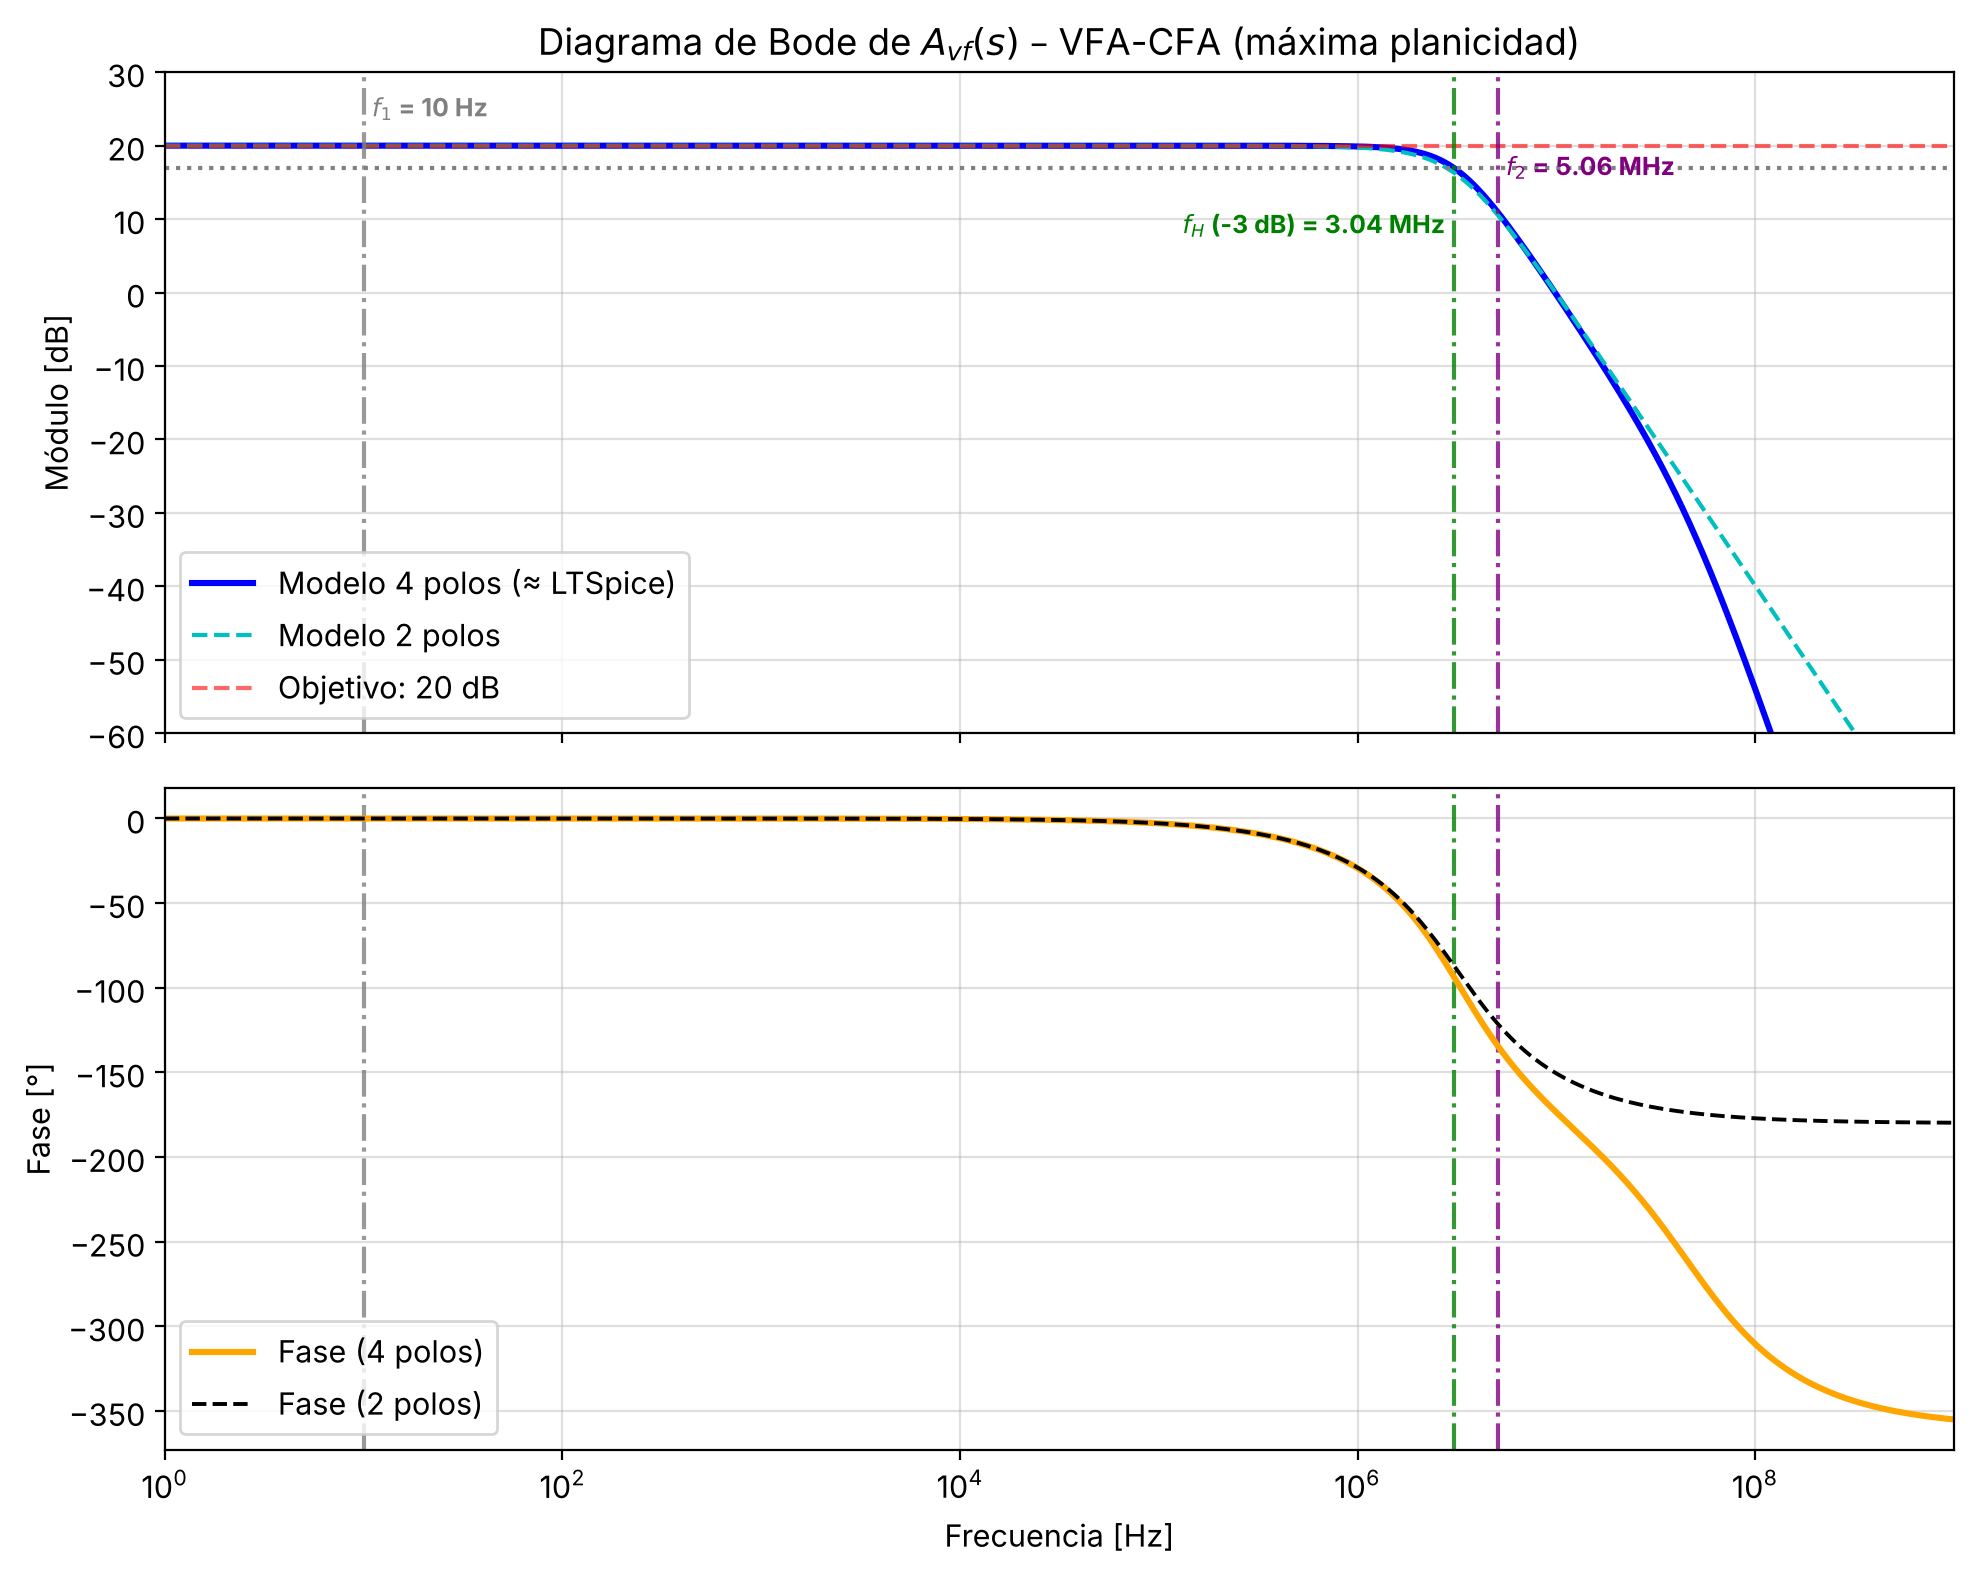

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magA'], 'b', lw=2.2, label='Modelo 4 polos (≈ LTSpice)')
ax1.semilogx(f, R2p['magA'], 'c--', lw=1.5, label='Modelo 2 polos')
ax1.axhline(Avf_dB, color='r', ls='--', alpha=0.6, label='Objetivo: 20 dB')
ax1.axhline(Avf_dB - 3, color='gray', ls=':')
ax1.set_ylim(-60, 30)
ax1.set_ylabel('Módulo [dB]')
ax1.set_title('Diagrama de Bode de $A_{vf}(s)$ – VFA-CFA (máxima planicidad)')

def etiq(nombre, fr):
    if fr < 1e3:  return f'{nombre} = {fr:.4g} Hz'
    if fr < 1e6:  return f'{nombre} = {fr/1e3:.4g} kHz'
    return f'{nombre} = {fr/1e6:.3g} MHz'

marcas = [(f1, '$f_1$', 'gray'), (fb, '$f_2$', 'purple'), (R4p['BW'], '$f_H$ (-3 dB)', 'green')]
for k, (fr, nombre, color) in enumerate(marcas):
    ax1.axvline(fr, color=color, ls='-.', alpha=0.8)
    ax2.axvline(fr, color=color, ls='-.', alpha=0.8)
    if nombre.startswith('$f_H'):
        ax1.text(fr/1.1, 24 - 8*k, etiq(nombre, fr), color=color, fontsize=9, weight='bold', ha='right')
    else:
        ax1.text(fr*1.1, 24 - 8*k, etiq(nombre, fr), color=color, fontsize=9, weight='bold')
ax1.legend(loc='lower left')

ax2.semilogx(f, R4p['faseA'], color='orange', lw=2.2, label='Fase (4 polos)')
ax2.semilogx(f, R2p['faseA'], 'k--', lw=1.4, label='Fase (2 polos)')
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c2_bode_lazo_cerrado.pdf')
plt.show()

### 6.2 Ganancia de lazo $T(s)$

El **margen de fase se define sobre $T(s)$**, no sobre $A_{vf}$. Este gráfico muestra:

* En el módulo: el cruce por 0 dB, que da la frecuencia crítica $f_{Gc}$ (línea verde). La línea roja es el ancho de banda potencial $f_g$ (cruce asintótico).
* En la fase: cuánto falta para −180° en ese punto, que es el **margen de fase** $M_\varphi$. También se marca el margen de ganancia $M_G$.

Debe coincidir con lo que se mide en LTSpice sobre el circuito de ganancia de lazo.

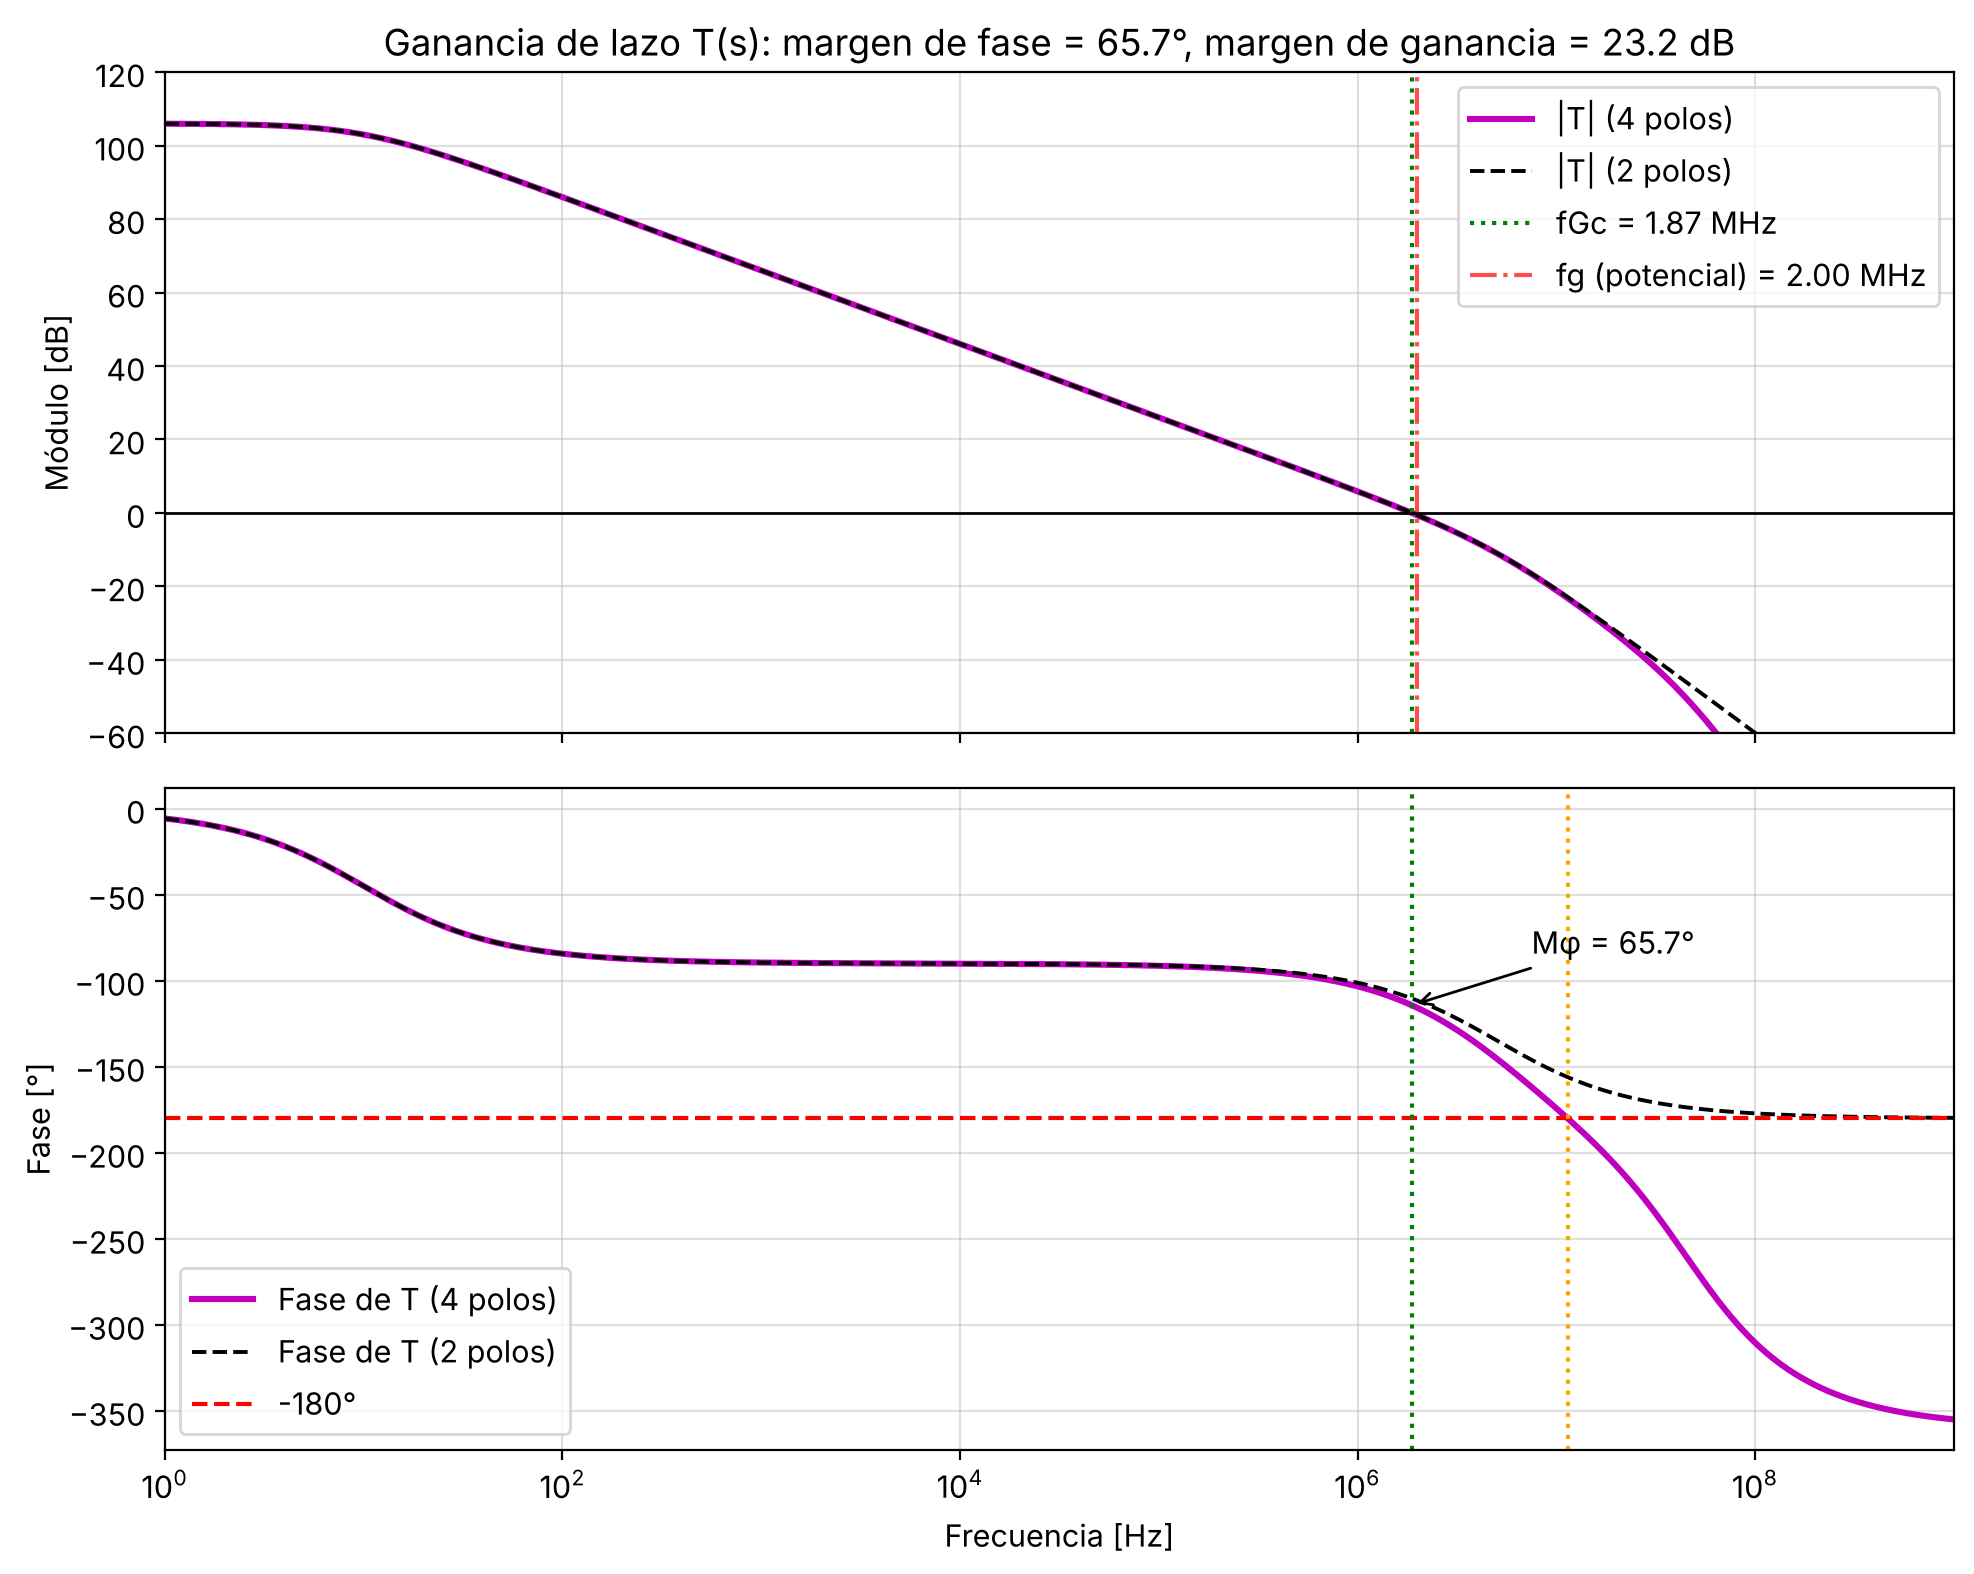

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

ax1.semilogx(f, R4p['magT'], 'm', lw=2.2, label='|T| (4 polos)')
ax1.semilogx(f, R2p['magT'], 'k--', lw=1.4, label='|T| (2 polos)')
ax1.axhline(0, color='k', lw=1)
ax1.axvline(R4p['fGc'], color='g', ls=':', label=f"fGc = {R4p['fGc']/1e6:.2f} MHz")
ax1.axvline(fg_pot, color='r', ls='-.', alpha=0.7, label=f'fg (potencial) = {fg_pot/1e6:.2f} MHz')
ax1.set_ylim(-60, 120); ax1.set_ylabel('Módulo [dB]')
ax1.set_title(f"Ganancia de lazo T(s): margen de fase = {R4p['Mphi']:.1f}°, margen de ganancia = {R4p['MG']:.1f} dB")
ax1.legend()

ax2.semilogx(f, R4p['faseT'], 'm', lw=2.2, label='Fase de T (4 polos)')
ax2.semilogx(f, R2p['faseT'], 'k--', lw=1.4, label='Fase de T (2 polos)')
ax2.axhline(-180, color='r', ls='--', label='-180°')
ax2.axvline(R4p['fGc'], color='g', ls=':')
ax2.axvline(R4p['fpc'], color='orange', ls=':')
ax2.annotate(f"Mφ = {R4p['Mphi']:.1f}°", xy=(R4p['fGc'], R4p['Mphi'] - 180),
             xytext=(R4p['fGc']*4, R4p['Mphi'] - 150), arrowprops=dict(arrowstyle='->'))
ax2.set_ylabel('Fase [°]'); ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_xlim(1, 1e9); ax2.legend(loc='lower left')

plt.tight_layout()
fig.savefig(f'{CARPETA}/c2_bode_ganancia_lazo.pdf')
plt.show()

### Sensibilidad al valor de $r_i$

Como el fabricante no publica $r_i$ (el apunte menciona 20 Ω y 30 Ω), se repite el modelo de 4 polos con distintos valores para ver cuánto cambian los resultados. **Si la diferencia es chica, el supuesto no es crítico.**

In [9]:
filas_ri = []
for ri_v in [1e-3, 10, 20, 30, 50]:
    n_, d_ = armar_4p(ri_v)
    T_, A_, dc_ = lazo(n_, d_)
    r_ = medir(T_, A_, dc_)
    filas_ri.append([f'{ri_v:g}', f"{(R2 + ri_v*G0):.0f}", f"{r_['fGc']/1e6:.3f}", f"{r_['Mphi']:.1f}",
                     f"{r_['MG']:.1f}", f"{r_['BW']/1e6:.3f}", f"{r_['pico']:.2f}"])
tabla_ri = pd.DataFrame(filas_ri, columns=['ri [Ω]', 'Reff [Ω]', 'fGc [MHz]', 'Margen de fase [°]',
                                           'Margen de ganancia [dB]', 'BW -3 dB [MHz]', 'Pico [dB]']).set_index('ri [Ω]')
print('TABLA – Sensibilidad al valor de ri (modelo de 4 polos)')
display(tabla_ri)

TABLA – Sensibilidad al valor de ri (modelo de 4 polos)


,Reff [Ω],fGc [MHz],Margen de fase [°],Margen de ganancia [dB],BW -3 dB [MHz],Pico [dB]
ri [Ω],,,,,,
0.001,820,1.875,67.0,26.2,2.962,0.00
10,1020,1.874,66.4,24.5,3.001,0.00
20,1220,1.873,65.7,23.2,3.039,0.00
30,1420,1.872,65.1,22.1,3.075,0.00
50,1820,1.869,63.9,20.4,3.142,0.00


## 7. Mediciones de LTSpice (consigna b.3)

**Esta es la única celda que hay que editar a mano.** Cargá acá lo que midas en LTSpice. Mientras estén en `None`, las tablas muestran `--`.

| Variable | Qué es | Dónde se mide en LTSpice |
|---|---|---|
| `fg_sim` | Frecuencia donde la ganancia de lazo cruza 0 dB | Circuito de ganancia de lazo |
| `Mphi_sim` | Margen de fase | Idem (`Phase Margin`) |
| `MG_sim`, `fpc_sim` | Margen de ganancia y frecuencia donde la fase de $T$ llega a −180° | Idem |
| `BW_sim` | Ancho de banda a −3 dB | Circuito a lazo cerrado, cursor a 17 dB |
| `Vpico_sim`, `Vest_sim` | Tensión pico y de régimen de la salida ante el escalón | Simulación temporal |
| `Vin_escalon` | Amplitud del escalón de entrada | Fuente de entrada |

**Sugerencia:** usá un escalón **chico** (p. ej. 0,1 V), para estar en pequeña señal y que el slew rate no distorsione el sobrepico.

In [10]:
# ====== EDITAR ACÁ con las mediciones de LTSpice (dejar None si todavía no se midió) ======
fg_sim      = 1873155.9    # [Hz]  cruce de 0 dB de la ganancia de lazo
Mphi_sim    = 65.7764    # [°]   margen de fase medido
MG_sim      = None    # [dB]  margen de ganancia medido
fpc_sim     = None    # [Hz]  frecuencia donde la fase de T llega a -180°
BW_sim      = 3.037e6    # [Hz]  ancho de banda a -3 dB (lazo cerrado)
Vpico_sim   = 1.0332811    # [V]   pico de la respuesta al escalón
Vest_sim    = 0.99978705    # [V]   valor de régimen
Vin_escalon = 0.1     # [V]   amplitud del escalón de entrada usado en LTSpice
# ===========================================================================================
print('Mediciones cargadas:', {k: v for k, v in dict(fg=fg_sim, Mphi=Mphi_sim, MG=MG_sim, BW=BW_sim, Vpico=Vpico_sim).items()})

Mediciones cargadas: {'fg': 1873155.9, 'Mphi': 65.7764, 'MG': None, 'BW': 3037000.0, 'Vpico': 1.0332811}


## 8. Respuesta al escalón y margen de fase estimado (consigna b.4)

**Idea:** un sistema subamortiguado supera su valor final al responder a un escalón. El tamaño de ese **sobrepico** indica el amortiguamiento, y éste el margen de fase:

1. Sobrepico porcentual: $\%OS=\dfrac{V_{pico}-V_{est}}{V_{est}}\cdot100$
2. Amortiguamiento: $\zeta=\dfrac{-\ln(\%OS/100)}{\sqrt{\pi^2+\ln^2(\%OS/100)}}$
3. Margen de fase: $M_\varphi=\arctan\!\left(\dfrac{2\zeta}{\sqrt{\sqrt{1+4\zeta^4}-2\zeta^2}}\right)$

La celda aplica esas ecuaciones al modelo de 2 polos, al de 4 polos (con `scipy`) y a la **medición de LTSpice** (si está cargada).

> **Si no hay sobrepico** (%OS < 0,05 %) no se puede estimar $\zeta$ con esta fórmula: significa $\zeta\gtrsim0{,}9$, es decir un margen de fase **superior a unos 73°**. La celda lo indica así.
> Estas relaciones son exactas solo para 2° orden; con 4 polos son una estimación.

TABLA 4 – Respuesta al escalón y margen de fase estimado


,Modelo 2 polos,Modelo 4 polos,LTSpice (medido)
Magnitud,,,
Vpico [V],1.0162,1.0336,1.0333
Vestacionario [V],1.0000,1.0000,0.9998
Sobrepico %OS,1.62,3.36,3.35
Amortiguamiento ζ,0.7953,0.7339,0.7341
Margen de fase estimado [°],69.66,66.88,66.89


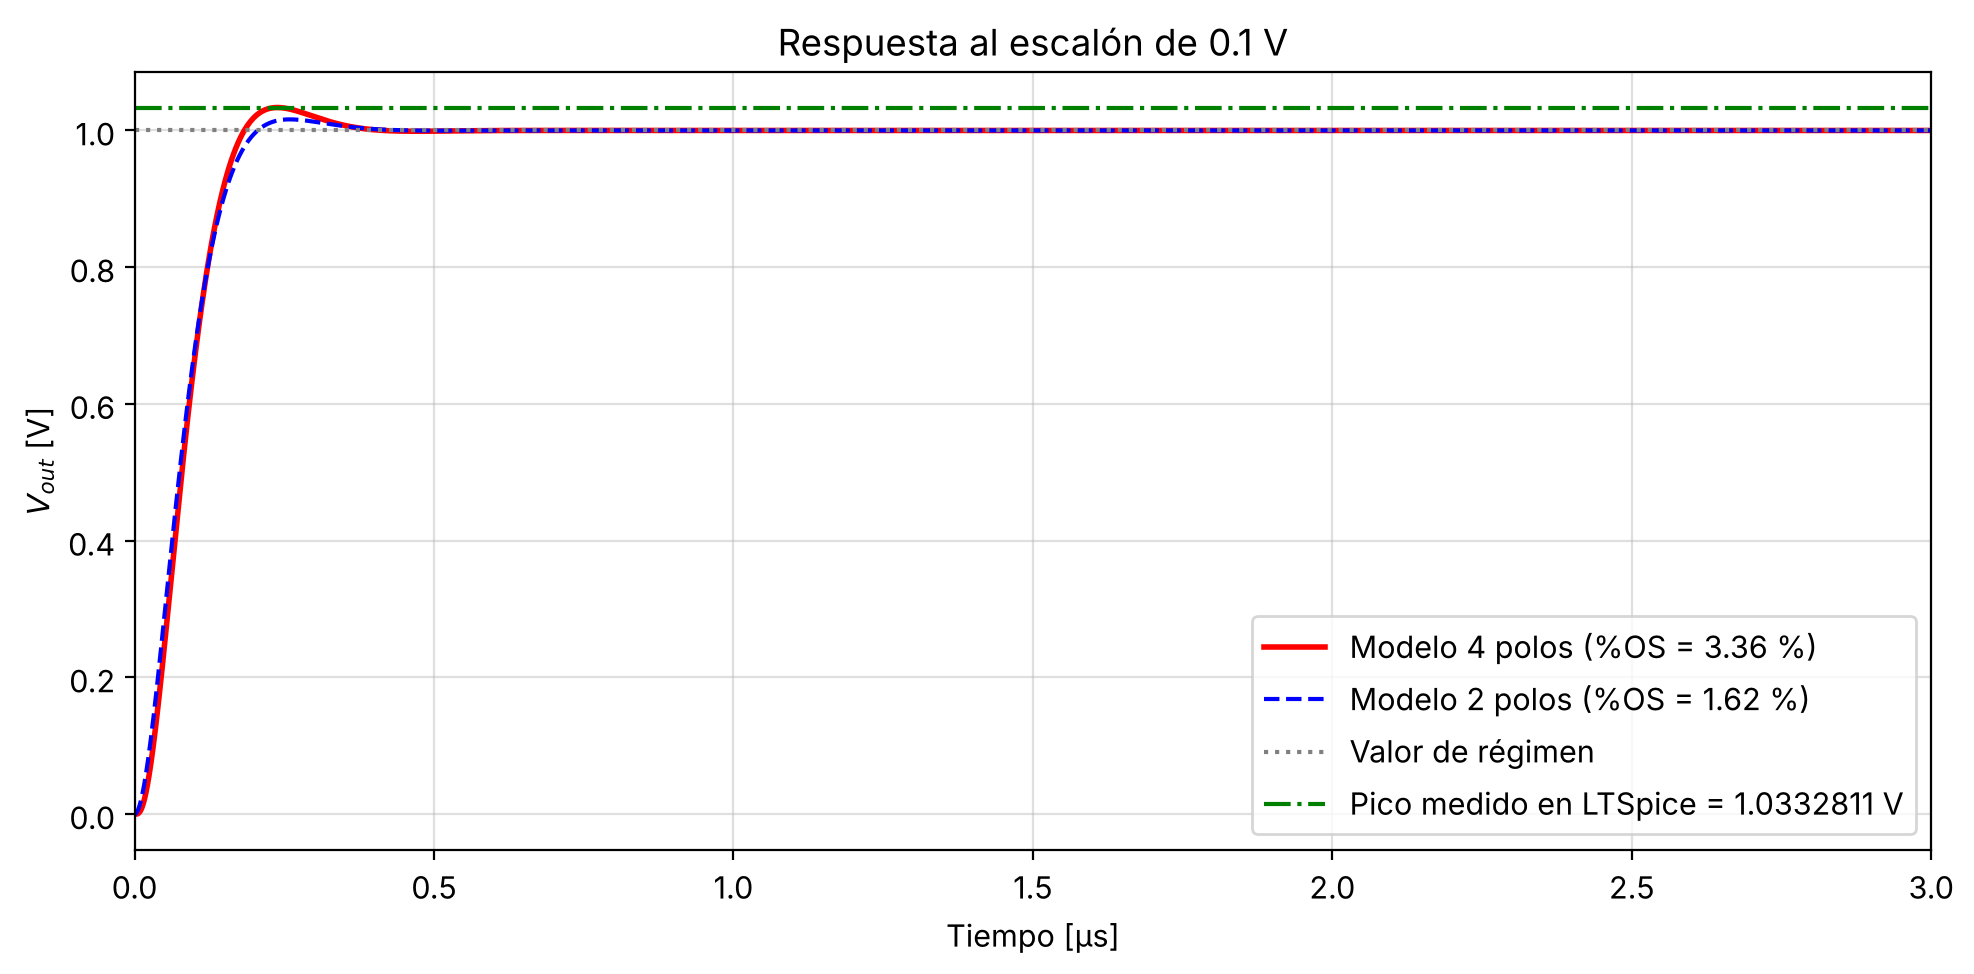

In [11]:
OS_MIN = 0.05                                        # [%] por debajo de esto se considera "sin sobrepico"

def escalon(den_cl, num_G, t_max=6e-6):
    t = np.linspace(0, t_max, 12001)
    t, y = signal.step(signal.TransferFunction(num_G*Vin_escalon, den_cl), T=t)
    return t, y

def sobrepico(Vpico, Vest):
    if Vpico is None or Vest is None:
        return None
    return max((Vpico - Vest)/Vest*100, 0.0)

def zeta_de_OS(OS):                                  # Ecuación del amortiguamiento
    if OS is None or OS < OS_MIN:
        return np.nan
    x = np.log(OS/100)
    return -x/np.sqrt(np.pi**2 + x**2)

def MF_de_zeta(z):                                   # Ecuación del margen de fase
    return np.degrees(np.arctan(2*z/np.sqrt(np.sqrt(1 + 4*z**4) - 2*z**2)))

def fmt(v, dec=2):
    return '--' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v:.{dec}f}'

t2, y2 = escalon(den_cl_2p, num_2p)
t4, y4 = escalon(den_cl_4p, num_4p)

OS_2p  = sobrepico(y2.max(), y2[-1])
OS_4p  = sobrepico(y4.max(), y4[-1])
OS_sim = sobrepico(Vpico_sim, Vest_sim)

z_2p, z_4p, z_sim = zeta_de_OS(OS_2p), zeta_de_OS(OS_4p), zeta_de_OS(OS_sim)
MF_2p, MF_4p = MF_de_zeta(z_2p), MF_de_zeta(z_4p)
MF_sim = MF_de_zeta(z_sim) if not np.isnan(z_sim) else np.nan

def txt_OS(OS):
    if OS is None: return '--'
    return 'sin sobrepico' if OS < OS_MIN else f'{OS:.2f}'

tabla_escalon = pd.DataFrame({
    'Magnitud': ['Vpico [V]', 'Vestacionario [V]', 'Sobrepico %OS', 'Amortiguamiento ζ', 'Margen de fase estimado [°]'],
    'Modelo 2 polos': [f'{y2.max():.4f}', f'{y2[-1]:.4f}', txt_OS(OS_2p), fmt(z_2p, 4), fmt(MF_2p)],
    'Modelo 4 polos': [f'{y4.max():.4f}', f'{y4[-1]:.4f}', txt_OS(OS_4p), fmt(z_4p, 4), fmt(MF_4p)],
    'LTSpice (medido)': [fmt(Vpico_sim, 4), fmt(Vest_sim, 4), txt_OS(OS_sim), fmt(z_sim, 4), fmt(MF_sim)],
}).set_index('Magnitud')

print('TABLA 4 – Respuesta al escalón y margen de fase estimado')
display(tabla_escalon)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(t4*1e6, y4, 'r', lw=2, label=f'Modelo 4 polos (%OS = {fmt(OS_4p)} %)')
ax.plot(t2*1e6, y2, 'b--', lw=1.5, label=f'Modelo 2 polos (%OS = {fmt(OS_2p)} %)')
ax.axhline(y4[-1], color='gray', ls=':', label='Valor de régimen')
if Vpico_sim is not None:
    ax.axhline(Vpico_sim, color='green', ls='-.', label=f'Pico medido en LTSpice = {Vpico_sim} V')
ax.set_xlim(0, 3); ax.set_xlabel('Tiempo [µs]'); ax.set_ylabel('$V_{out}$ [V]')
ax.set_title(f'Respuesta al escalón de {Vin_escalon:g} V'); ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(f'{CARPETA}/c2_escalon_teorico.pdf')
plt.show()

## 9. Tabla final: teoría vs. simulación

Se juntan todos los resultados en una sola tabla, uno por fila. Para cada magnitud se muestran el valor **analítico** (fórmulas cerradas, sección 3), el del **modelo de 4 polos** (sección 5) y el medido en **LTSpice** (sección 7). Los errores se calculan como
$$\varepsilon=\frac{\text{teórico}-\text{simulado}}{\text{simulado}}\cdot100$$
(igual que en el informe). Si todavía no se cargó una medición, la celda muestra `--`.

Esta es la tabla que va en el informe. Se guarda también como `.csv` y `.tex`.

In [12]:
def error(teo, sim):
    if sim is None or teo is None or (isinstance(teo, float) and np.isnan(teo)) or (isinstance(sim, float) and np.isnan(sim)):
        return '--'
    return f'{(teo - sim)/sim*100:+.1f}'

def texto(v, esc, dec):
    return '--' if (v is None or (isinstance(v, float) and np.isnan(v))) else f'{v*esc:.{dec}f}'

OS_txt = lambda v: texto(v, 1, 2)

# (nombre, analítico, modelo 4 polos, LTSpice, factor de escala, decimales)
filas = [
    ('Ancho de banda potencial fg [MHz]',            fg_pot,   None,         None,      1e-6, 3),
    ('Cruce de T, fGc (exacto) [MHz]',               fGc_ex,   R4p['fGc'],   fg_sim,    1e-6, 3),
    ('Margen de fase del lazo [°]',                  Mphi_an,  R4p['Mphi'],  Mphi_sim,  1,    2),
    ('Frecuencia de los polos fp [MHz]',             fp,       R4p['fp'],    None,      1e-6, 3),
    ('Ancho de banda real fH (-3 dB) [MHz]',         fH_an,    R4p['BW'],    BW_sim,    1e-6, 3),
    ('Sobrepico %OS [%]',                            OS_2p,    OS_4p,        OS_sim,    1,    2),
    ('Margen de fase desde el escalón [°]',          MF_2p,    MF_4p,        MF_sim,    1,    2),
]

tabla_final = pd.DataFrame({
    'Magnitud':        [r[0] for r in filas],
    'Analítico':       [texto(r[1], r[4], r[5]) for r in filas],
    'Modelo 4 polos':  [texto(r[2], r[4], r[5]) for r in filas],
    'LTSpice':         [texto(r[3], r[4], r[5]) for r in filas],
    'Error anal. [%]': [error(r[1], r[3]) for r in filas],
    'Error 4 polos [%]': [error(r[2], r[3]) for r in filas],
}).set_index('Magnitud')

print('TABLA FINAL – Caso 2 (VFA-CFA): teoría vs. simulación')
display(tabla_final)
print(f'\nMargen de ganancia (modelo de 4 polos): {R4p["MG"]:.1f} dB en {R4p["fpc"]/1e6:.2f} MHz')

TABLA FINAL – Caso 2 (VFA-CFA): teoría vs. simulación


,Analítico,Modelo 4 polos,LTSpice,Error anal. [%],Error 4 polos [%]
Magnitud,,,,,
Ancho de banda potencial fg [MHz],2.000,--,--,--,--
"Cruce de T, fGc (exacto) [MHz]",1.875,1.873,1.873,+0.1,-0.0
Margen de fase del lazo [°],69.66,65.74,65.78,+5.9,-0.1
Frecuencia de los polos fp [MHz],3.181,3.165,--,--,--
Ancho de banda real fH (-3 dB) [MHz],2.791,3.039,3.037,-8.1,+0.1
Sobrepico %OS [%],1.62,3.36,3.35,-51.6,+0.2
Margen de fase desde el escalón [°],69.66,66.88,66.89,+4.1,-0.0



Margen de ganancia (modelo de 4 polos): 23.2 dB en 11.39 MHz


## 10. Guardar las tablas para el informe

La celda guarda las tablas en `salidas_caso2`: `.csv` (para abrir en Excel) y `.tex` (para incluir en LaTeX; requiere `booktabs`). Las figuras ya se guardaron como PDF en las secciones anteriores.

Si estás en **Google Colab**, además descarga todo en un `.zip`. Fuera de Colab no hace nada más (el aviso de "google.colab" en VS Code se puede ignorar).

In [13]:
def guardar(df, nombre, titulo, etiqueta):
    df.to_csv(f'{CARPETA}/{nombre}.csv', encoding='utf-8-sig')
    cols = ' & '.join(['Magnitud'] + list(df.columns)) + r' \\'
    lineas = [r'\begin{table}[H]', r'\centering', r'\begin{tabular}{l' + 'c'*len(df.columns) + '}', r'\toprule', cols, r'\midrule']
    for idx, fila in df.iterrows():
        lineas.append(' & '.join([str(idx)] + [str(v) for v in fila.values]).replace('%', r'\%').replace('°', r'$^\circ$').replace('_', r'\_') + r' \\')
    lineas += [r'\bottomrule', r'\end{tabular}', rf'\caption{{{titulo}}}', rf'\label{{{etiqueta}}}', r'\end{table}']
    open(f'{CARPETA}/{nombre}.tex', 'w', encoding='utf-8').write('\n'.join(lineas))

guardar(tabla_diseno,     'tabla_diseno',     'Parámetros de diseño (VFA-CFA).', 'tab:diseno_c2')
guardar(tabla_analitica,  'tabla_analitica',  'Resultados analíticos (VFA-CFA).', 'tab:analitica_c2')
guardar(tabla_modelos,    'tabla_modelos',    'Resultados numéricos: modelo de 2 polos y de 4 polos.', 'tab:modelos_c2')
guardar(tabla_escalon,    'tabla_escalon',    'Respuesta al escalón y margen de fase estimado.', 'tab:escalon_c2')
guardar(tabla_final,      'tabla_final',      'Comparación entre teoría y simulación (VFA-CFA).', 'tab:final_c2')
guardar(tabla_ri,         'tabla_sensibilidad_ri', 'Sensibilidad de los resultados al valor de $r_i$.', 'tab:ri_c2')

print('Archivos en', CARPETA + ':')
for nombre in sorted(os.listdir(CARPETA)):
    print('  ', nombre)

try:    # solo funciona en Google Colab
    import shutil
    from google.colab import files  # type: ignore
    shutil.make_archive('salidas_caso2', 'zip', CARPETA)
    files.download('salidas_caso2.zip')
except ImportError:
    pass

Archivos en salidas_caso2:
   c2_bode_ganancia_lazo.pdf
   c2_bode_lazo_cerrado.pdf
   c2_escalon_teorico.pdf
   tabla_analitica.csv
   tabla_analitica.tex
   tabla_diseno.csv
   tabla_diseno.tex
   tabla_escalon.csv
   tabla_escalon.tex
   tabla_final.csv
   tabla_final.tex
   tabla_modelos.csv
   tabla_modelos.tex
   tabla_sensibilidad_ri.csv
   tabla_sensibilidad_ri.tex


## 11. Qué mirar para la conclusión del Caso 2

La celda siguiente imprime, con los números de esta ejecución, los puntos que conviene discutir. Después de cargar las mediciones de LTSpice, volvé a ejecutar las celdas desde la sección 7 para actualizar las tablas.

In [14]:
print('1) DISEÑO: G0 = %.1f (R1 = %.1f ohm, R2 = %.0f ohm) da fg = K·G0·fT = %.2f MHz; el tope de MPM es G0 = %.1f (fg <= f2/2 = %.2f MHz).' % (G0, R1, R2, fg_pot/1e6, G0_max, f2/2e6))
print('2) POTENCIAL vs. REAL: fg = %.2f MHz (potencial); el ancho de banda real a -3 dB es %.2f MHz (analítico) / %.2f MHz (4 polos), porque con Qp = %.2f la respuesta es plana y el BW supera a fg.' % (fg_pot/1e6, fH_an/1e6, R4p['BW']/1e6, Q))
print('3) MARGEN DE FASE del lazo: %.1f° (2 polos) vs. %.1f° (4 polos); el CFA agrega atraso de fase (sus polos y Reff) que el modelo simple desprecia.' % (Mphi_an, R4p['Mphi']))
print('4) ESCALÓN: sobrepico %s %% (4 polos) -> margen de fase estimado %s°.' % (fmt(OS_4p), fmt(MF_4p)))
print('5) SUPUESTO ri = %.0f ohm: ver la tabla de sensibilidad; el margen de fase varía entre %s° y %s° para ri entre 1 mΩ y 50 Ω.' % (ri, tabla_ri['Margen de fase [°]'].iloc[-1], tabla_ri['Margen de fase [°]'].iloc[0]))
print('6) ESTABILIDAD DEL CFA: con R2 = %.0f ohm el CFA solo tiene un margen de fase de %.1f°.' % (R2, Mphi_cfa))

1) DISEÑO: G0 = 20.0 (R1 = 43.2 ohm, R2 = 820 ohm) da fg = K·G0·fT = 2.00 MHz; el tope de MPM es G0 = 25.3 (fg <= f2/2 = 2.53 MHz).
2) POTENCIAL vs. REAL: fg = 2.00 MHz (potencial); el ancho de banda real a -3 dB es 2.79 MHz (analítico) / 3.04 MHz (4 polos), porque con Qp = 0.63 la respuesta es plana y el BW supera a fg.
3) MARGEN DE FASE del lazo: 69.7° (2 polos) vs. 65.7° (4 polos); el CFA agrega atraso de fase (sus polos y Reff) que el modelo simple desprecia.
4) ESCALÓN: sobrepico 3.36 % (4 polos) -> margen de fase estimado 66.88°.
5) SUPUESTO ri = 20 ohm: ver la tabla de sensibilidad; el margen de fase varía entre 63.9° y 67.0° para ri entre 1 mΩ y 50 Ω.
6) ESTABILIDAD DEL CFA: con R2 = 820 ohm el CFA solo tiene un margen de fase de 72.5°.
